# HW2 — Uniform Convergence and the Limits of Learning

**Statistical and Machine Learning** — M2 IM / IMDS / MIAGE, Université de Haute-Alsace

**Author:** Amina MENACER

---

**Goal.** Study by repeated probabilistic simulation (1) how empirical risks fluctuate around true risks and why a finite hypothesis class enjoys **uniform convergence**, (2) the **No-Free-Lunch** phenomenon on completely random target functions, and (3) how an appropriate **inductive bias** makes generalization to unseen inputs possible.

**Outline**

*Part I — Simulating uniform convergence*
1. Empirical risk as a random variable
2. Deviation between empirical and true risk (Hoeffding)
3. From one hypothesis to uniform convergence
4. Effect of the size of the hypothesis class
5. Experimental sample complexity

*Part II — Simulating No-Free-Lunch*

6. Seen and unseen inputs
7. Error on unseen inputs
8. Changing the prediction on unseen inputs

*Part III — Introducing prior knowledge*

9. Learning with a matching inductive bias
10. Random targets vs. structured targets
11. Final analysis

Only `numpy` and `matplotlib` are used. Every experiment has its own seeded random generator, so the results do not depend on the order in which the cells are run.

## 0. Setup and experimental parameters

| Parameter | Value | Justification |
|---|---|---|
| $\varepsilon$ | 0.05 | A 5% accuracy level: small enough that small samples visibly fail, large enough that the transition happens for $m$ of a few hundreds, which is cheap to simulate. |
| $\delta$ | 0.05 | Usual 95% confidence; used for the sample-complexity experiments. |
| true risks $p$ | 0.05, 0.2, 0.5 | A small, a medium and the worst-case risk: the variance $p(1-p)$ of one 0-1 loss is largest at $p=0.5$. |
| sample sizes $m$ | 10 to 3000 | Covers the whole range from "almost always non-representative" to "almost always representative". |
| class sizes $\lvert\mathcal H\rvert$ | 5, 10, 20, 50, 100, 500 | Two orders of magnitude, to see the $\ln\lvert\mathcal H\rvert$ dependence. |
| domain size $N$ | 20, 100, 500 (main: 100) | Small, medium and large domains for Parts II–III. |
| repetitions | 20 000 (one hypothesis), 2 000–10 000 (classes), 5 000 (Parts II–III) | Monte Carlo standard error at most $\sqrt{0.25/2000}\approx 0.011$, and about $0.003$ near $\delta=0.05$ with 4 000 runs. |

**Exact checks.** Under the simplified model of the homework, $E_j \sim \text{Binomial}(m, p_j)$, so every probability we estimate also has an exact value: $P(|E_j/m - p_j|>\varepsilon)$ is a finite sum of binomial probabilities, and if the $E_j$ are independent, $P(\Delta_S > \varepsilon) = 1 - \prod_j \big(1 - P(|E_j/m-p_j|>\varepsilon)\big)$. We plot these exact values as lines and the Monte Carlo estimates as dots: their agreement validates the code.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import log, ceil, sqrt

SEED = 42

def make_rng(tag):
    # One independent random generator per experiment.
    # Each experiment gets its own stream, so results do not depend on the order cells are run in.
    return np.random.default_rng([SEED, tag])

# ---- Part I: uniform convergence ----
EPS = 0.05            # accuracy level epsilon
DELTA = 0.05          # confidence parameter delta
R = 20_000            # Monte Carlo repetitions for one hypothesis
P_LIST = [0.05, 0.2, 0.5]          # true risks used in Sections 1-2
M_LIST = [10, 50, 200, 1000]       # sample sizes shown in Section 1

# ---- Parts II-III: No-Free-Lunch and inductive bias ----
N = 100               # domain size X = {1, ..., N}
N_LIST = [20, 100, 500]
R2 = 5_000            # Monte Carlo repetitions (one new target per repetition)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


In [2]:
# Exact binomial computations (used to check the Monte Carlo estimates).
M_MAX = 4000
LOG_FACT = np.concatenate([[0.0], np.cumsum(np.log(np.arange(1, M_MAX + 1)))])

def binom_pmf(m, p):
    # pmf of Binomial(m, p) for every p in the array p -> shape (len(p), m+1)
    p = np.atleast_1d(np.asarray(p, dtype=float))[:, None]
    k = np.arange(m + 1)[None, :]
    log_c = LOG_FACT[m] - LOG_FACT[k] - LOG_FACT[m - k]
    with np.errstate(divide="ignore", invalid="ignore"):
        lp = log_c + k * np.log(p) + (m - k) * np.log1p(-p)
    return np.exp(lp)

def is_large_deviation(E, m, p, eps):
    # |E/m - p| > eps, written on integers to avoid rounding issues at the boundary
    return np.round(np.abs(E - m * p), 9) > np.round(m * eps, 9)

def exact_dev_prob(m, p, eps):
    # P(|L_S(h) - L_D(h)| > eps) for E ~ Binomial(m, p); one value per p
    p = np.atleast_1d(p)
    k = np.arange(m + 1)
    mask = is_large_deviation(k[None, :], m, p[:, None], eps)
    return (binom_pmf(m, p) * mask).sum(axis=1)

def exact_uc_fail(m, ps, eps):
    # P(max_h |L_S(h) - L_D(h)| > eps) when the K empirical risks are independent
    return 1 - np.prod(1 - exact_dev_prob(m, ps, eps))

def hoeffding(m, eps, K=1):
    # finite-class bound 2|H| exp(-2 m eps^2), capped at 1 (a probability)
    return np.minimum(1.0, 2 * K * np.exp(-2 * np.asarray(m) * eps ** 2))


# Part I — Simulating uniform convergence

## 1. Empirical risk as a random variable

For a fixed hypothesis $h_j$ with true risk $L_{\mathcal D}(h_j)=p_j$, the number of mistakes on a sample of size $m$ is $E_j\sim\text{Binomial}(m,p_j)$ and $L_S(h_j)=E_j/m$. Hence
$$\mathbb E[L_S(h_j)] = p_j, \qquad \text{std}(L_S(h_j)) = \sqrt{\frac{p_j(1-p_j)}{m}}.$$
We simulate $R = 20\,000$ samples for each $(p, m)$.

In [3]:
rng = make_rng(1)
sim = {}            # sim[(p, m)] = R simulated values of L_S(h)
print(f"{'p = L_D':>8} | {'m':>5} | {'mean L_S':>9} | {'std L_S (MC)':>12} | {'sqrt(p(1-p)/m)':>14}")
for p in P_LIST:
    for m in M_LIST:
        ls = rng.binomial(m, p, size=R) / m
        sim[(p, m)] = ls
        print(f"{p:>8} | {m:>5} | {ls.mean():>9.4f} | {ls.std():>12.4f} | {sqrt(p*(1-p)/m):>14.4f}")


 p = L_D |     m |  mean L_S | std L_S (MC) | sqrt(p(1-p)/m)
    0.05 |    10 |    0.0505 |       0.0693 |         0.0689
    0.05 |    50 |    0.0500 |       0.0307 |         0.0308
    0.05 |   200 |    0.0501 |       0.0154 |         0.0154
    0.05 |  1000 |    0.0500 |       0.0069 |         0.0069
     0.2 |    10 |    0.1998 |       0.1273 |         0.1265
     0.2 |    50 |    0.1998 |       0.0563 |         0.0566
     0.2 |   200 |    0.2000 |       0.0281 |         0.0283
     0.2 |  1000 |    0.2001 |       0.0127 |         0.0126
     0.5 |    10 |    0.5000 |       0.1579 |         0.1581
     0.5 |    50 |    0.5000 |       0.0715 |         0.0707
     0.5 |   200 |    0.5004 |       0.0353 |         0.0354
     0.5 |  1000 |    0.5000 |       0.0158 |         0.0158


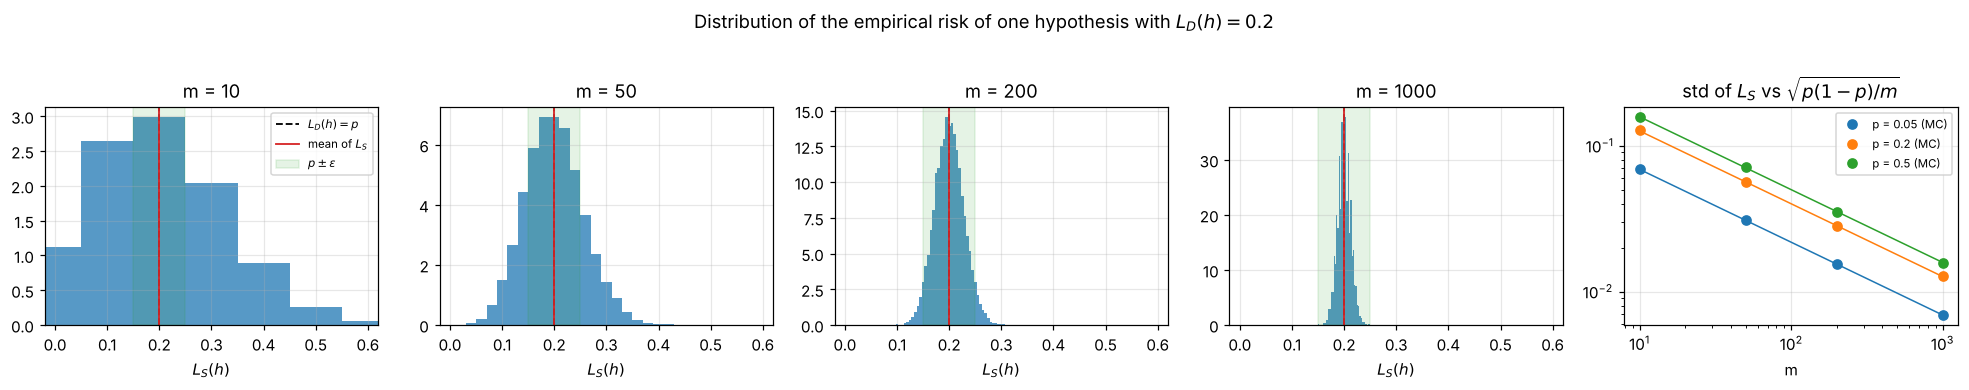

In [4]:
p0 = 0.2
fig, axes = plt.subplots(1, len(M_LIST) + 1, figsize=(18, 3.4))
for ax, m in zip(axes, M_LIST):
    ls = sim[(p0, m)]
    bins = np.arange(-0.5, m + 1.5) / m if m <= 200 else 40
    ax.hist(ls, bins=bins, density=True, color="tab:blue", alpha=0.75)
    ax.axvline(p0, color="k", ls="--", lw=1.2, label=r"$L_D(h)=p$")
    ax.axvline(ls.mean(), color="tab:red", lw=1.2, label="mean of $L_S$")
    ax.axvspan(p0 - EPS, p0 + EPS, color="tab:green", alpha=0.12, label=r"$p\pm\varepsilon$")
    ax.set_xlim(-0.02, 0.62); ax.set_title(f"m = {m}"); ax.set_xlabel(r"$L_S(h)$")
axes[0].legend(fontsize=7.5)
ax = axes[-1]
mm = np.array(M_LIST)
for p, c in zip(P_LIST, ["tab:blue", "tab:orange", "tab:green"]):
    ax.loglog(mm, [sim[(p, m)].std() for m in M_LIST], "o", color=c, label=f"p = {p} (MC)")
    ax.loglog(mm, np.sqrt(p * (1 - p) / mm), "-", color=c, lw=1)
ax.set_xlabel("m"); ax.set_title(r"std of $L_S$ vs $\sqrt{p(1-p)/m}$"); ax.legend(fontsize=7.5)
fig.suptitle(rf"Distribution of the empirical risk of one hypothesis with $L_D(h)={p0}$", y=1.03)
plt.tight_layout(); plt.show()


**Observation.** For every $p$ and every $m$, the mean of the simulated $L_S(h)$ equals $p$ up to the third decimal (for example $0.1998$ for $p=0.2$, $m=10$), and the empirical standard deviation matches $\sqrt{p(1-p)/m}$ (for $p=0.5$: $0.158, 0.072, 0.035, 0.016$ for $m = 10, 50, 200, 1000$). On the histograms, the distribution is wide and discrete for $m=10$ (only 11 possible values, $L_S \in \{0, 0.1, \dots\}$), and becomes a narrow bell centred on $p$ for $m=1000$, almost entirely inside $[p-\varepsilon, p+\varepsilon]$. On the log-log plot the standard deviation follows a straight line of slope $-1/2$.

**Explanation.** $L_S(h)$ is an average of $m$ i.i.d. 0-1 losses with mean $p$. Its expectation does not depend on $m$, but its variance $p(1-p)/m$ does: multiplying $m$ by 100 divides the spread by 10. The spread is largest for $p=0.5$ and smallest for $p=0.05$, because $p(1-p)$ is maximal at $1/2$.

**Link to the course.** This is the result of TD1 (Exercise 2): for a fixed $h$, $L_S(h)$ is an unbiased estimator of $L_{\mathcal D}(h)$. The decreasing spread is what the law of large numbers says, and Section 2 quantifies it with Hoeffding's inequality.

## 2. Deviation between empirical and true risk

For each simulated sample we compute $|L_S(h)-L_{\mathcal D}(h)|$ and estimate $P(|L_S(h)-L_{\mathcal D}(h)|>\varepsilon)$ for $\varepsilon = 0.05$. Hoeffding's inequality (losses in $[0,1]$) gives
$$P\big(|L_S(h) - L_{\mathcal D}(h)| > \varepsilon\big) \le 2e^{-2m\varepsilon^2}.$$

In [5]:
M_DEV = np.array([10, 20, 50, 100, 150, 200, 300, 400, 500, 750, 1000, 1500, 2000])
rng = make_rng(2)
dev = {}
for p in P_LIST:
    mc, ex = [], []
    for m in M_DEV:
        E = rng.binomial(m, p, size=R)
        mc.append(np.mean(is_large_deviation(E, m, p, EPS)))
        ex.append(exact_dev_prob(m, p, EPS)[0])
    dev[p] = (np.array(mc), np.array(ex))

print(f"eps = {EPS}.  P(|L_S - L_D| > eps): Monte Carlo / exact, and the Hoeffding bound")
print(f"{'m':>5} | " + " | ".join(f"{'p='+str(p)+' MC':>10} {'exact':>8}" for p in P_LIST) + f" | {'Hoeffding':>9}")
for i, m in enumerate(M_DEV):
    row = " | ".join(f"{dev[p][0][i]:>10.4f} {dev[p][1][i]:>8.4f}" for p in P_LIST)
    print(f"{m:>5} | {row} | {hoeffding(m, EPS):>9.4f}")


eps = 0.05.  P(|L_S - L_D| > eps): Monte Carlo / exact, and the Hoeffding bound
    m |  p=0.05 MC    exact |   p=0.2 MC    exact |   p=0.5 MC    exact | Hoeffding
   10 |     0.0856   0.0861 |     0.7018   0.6980 |     0.7562   0.7539 |    1.0000
   20 |     0.0762   0.0755 |     0.4049   0.4019 |     0.4996   0.5034 |    1.0000
   50 |     0.0365   0.0378 |     0.3770   0.3765 |     0.4814   0.4799 |    1.0000
  100 |     0.0116   0.0115 |     0.1657   0.1679 |     0.2698   0.2713 |    1.0000
  150 |     0.0039   0.0036 |     0.1239   0.1249 |     0.2230   0.2205 |    0.9447
  200 |     0.0015   0.0012 |     0.0639   0.0628 |     0.1368   0.1374 |    0.7358
  300 |     0.0001   0.0001 |     0.0240   0.0250 |     0.0746   0.0733 |    0.4463
  400 |     0.0000   0.0000 |     0.0096   0.0103 |     0.0403   0.0402 |    0.2707
  500 |     0.0000   0.0000 |     0.0057   0.0043 |     0.0237   0.0225 |    0.1642
  750 |     0.0000   0.0000 |     0.0008   0.0006 |     0.0063   0.0061 |    0.0

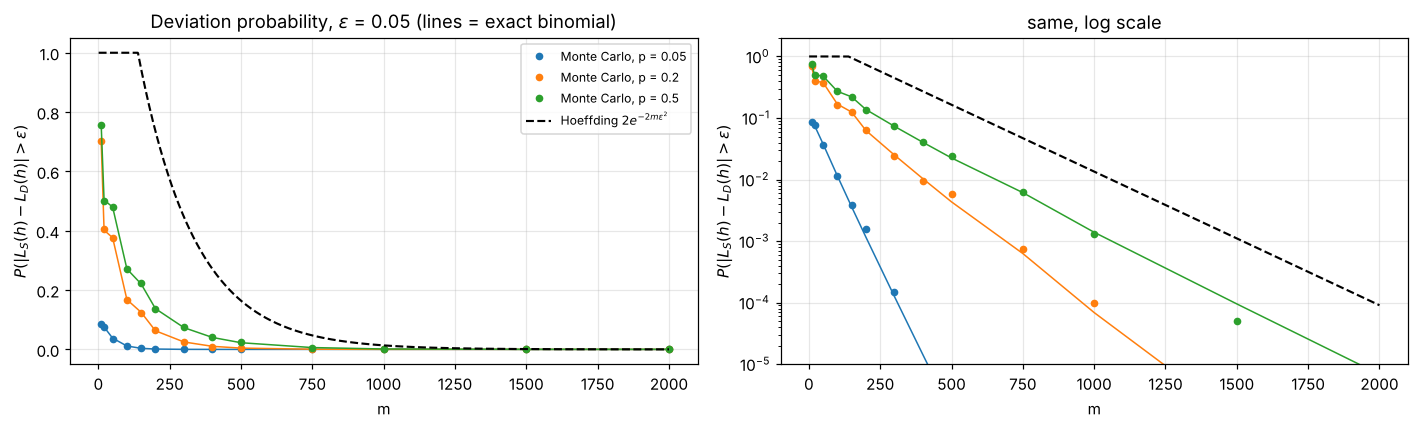

Smallest m with P(|L_S - L_D| > 0.05) <= 0.05:
  p = 0.05: exact m = 40
  p = 0.2 : exact m = 232


  p = 0.5 : exact m = 371
  Hoeffding (any p): m = 738


In [6]:
mm = np.arange(1, 2001)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, scale in zip(axes, ["linear", "log"]):
    for p, c in zip(P_LIST, ["tab:blue", "tab:orange", "tab:green"]):
        ax.plot(M_DEV, dev[p][0], "o", ms=4, color=c, label=f"Monte Carlo, p = {p}")
        ax.plot(M_DEV, dev[p][1], "-", lw=1, color=c)
    ax.plot(mm, hoeffding(mm, EPS), "k--", lw=1.4, label=r"Hoeffding $2e^{-2m\varepsilon^2}$")
    ax.set_yscale(scale); ax.set_xlabel("m"); ax.set_ylabel(r"$P(|L_S(h)-L_D(h)|>\varepsilon)$")
    if scale == "log": ax.set_ylim(1e-5, 2)
axes[0].set_title(r"Deviation probability, $\varepsilon$ = %.2f (lines = exact binomial)" % EPS)
axes[1].set_title("same, log scale")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# How conservative is Hoeffding? Compare the sample size each one requires to reach delta.
m_fine = np.arange(1, 1601)
print(f"Smallest m with P(|L_S - L_D| > {EPS}) <= {DELTA}:")
for p in P_LIST:
    exact_curve = np.array([exact_dev_prob(m, p, EPS)[0] for m in m_fine])
    print(f"  p = {p:<4}: exact m = {m_fine[np.argmax(exact_curve <= DELTA)]}")
print(f"  Hoeffding (any p): m = {ceil(log(2 / DELTA) / (2 * EPS**2))}")


**Observation.** The Monte Carlo estimates agree with the exact binomial values (for example $0.2698$ vs $0.2713$ for $p=0.5$, $m=100$), and all of them stay below the Hoeffding curve for every $m$. The bound is equal to 1 (useless) up to $m \approx 140$, while the true probability is already $0.17$ for $p=0.2$ at $m=100$. To reach $\delta = 0.05$, a single hypothesis really needs $m = 40$ ($p=0.05$), $232$ ($p=0.2$) or $371$ ($p=0.5$), whereas Hoeffding asks for $m = 738$ in all cases, i.e. 2 to 18 times more. On the log scale, both the exact curves and the bound decrease linearly in $m$, so the decrease is exponential.

**Explanation.** Hoeffding only uses the fact that the losses are in $[0,1]$: it does not know $p$, so it must cover the worst case, and it is derived from an exponential inequality that is not tight. The exact probability is close to the bound's shape for $p=0.5$, where the variance is maximal, and much smaller for $p=0.05$, where the empirical risk hardly moves. The curves are not perfectly smooth for small $m$ because $L_S$ only takes the values $k/m$, so the event $|k/m-p|>\varepsilon$ changes by jumps.

**Link to the course.** The bound is **valid but conservative**: it is a sufficient condition, not the exact behaviour. Its strength is that it holds for every distribution and decreases exponentially in $m\varepsilon^2$, which is what Section 3 needs to control many hypotheses at once.

## 3. From one hypothesis to uniform convergence

We now take $|\mathcal H| = 20$ hypotheses with true risks spread evenly between $0.05$ and $0.5$, simulate their empirical risks on the same sample size (independently, as in the homework model), and compute
$$\Delta_S = \max_{h\in\mathcal H} |L_S(h) - L_{\mathcal D}(h)|.$$
$S$ is $\varepsilon$-representative exactly when $\Delta_S \le \varepsilon$. The finite-class bound is $P(\Delta_S > \varepsilon) \le 2|\mathcal H|e^{-2m\varepsilon^2}$.

In [7]:
K3 = 20
P_H = np.linspace(0.05, 0.5, K3)        # true risks of the K hypotheses
M_UC = np.array([20, 50, 100, 200, 300, 400, 500, 600, 800, 1000, 1200, 1500])
R3 = 10_000
rng = make_rng(3)

uc_mc, uc_ex, single_worst, frac_argmax_ok = [], [], [], []
for m in M_UC:
    E = rng.binomial(m, P_H, size=(R3, K3))          # one row = one training sample, one column = one hypothesis
    gaps = np.abs(E / m - P_H)
    big = is_large_deviation(E, m, P_H, EPS)
    uc_mc.append(np.mean(big.any(axis=1)))           # Delta_S > eps  <=>  at least one hypothesis deviates
    uc_ex.append(exact_uc_fail(m, P_H, EPS))
    single_worst.append(exact_dev_prob(m, P_H, EPS).max())
uc_mc, uc_ex, single_worst = map(np.array, (uc_mc, uc_ex, single_worst))

print(f"|H| = {K3}, true risks from {P_H[0]} to {P_H[-1]}, eps = {EPS}")
print(f"{'m':>5} | {'P(Delta>eps) MC':>15} | {'exact':>7} | {'worst single h':>14} | {'2|H|exp(-2m eps^2)':>18}")
for i, m in enumerate(M_UC):
    print(f"{m:>5} | {uc_mc[i]:>15.4f} | {uc_ex[i]:>7.4f} | {single_worst[i]:>14.4f} | {hoeffding(m, EPS, K3):>18.4f}")


|H| = 20, true risks from 0.05 to 0.5, eps = 0.05
    m | P(Delta>eps) MC |   exact | worst single h | 2|H|exp(-2m eps^2)
   20 |          1.0000 |  1.0000 |         0.6620 |             1.0000
   50 |          1.0000 |  1.0000 |         0.4808 |             1.0000
  100 |          0.9943 |  0.9947 |         0.3169 |             1.0000
  200 |          0.8762 |  0.8740 |         0.1569 |             1.0000
  300 |          0.6093 |  0.6157 |         0.0831 |             1.0000
  400 |          0.3686 |  0.3780 |         0.0451 |             1.0000
  500 |          0.2142 |  0.2173 |         0.0251 |             1.0000
  600 |          0.1188 |  0.1218 |         0.0142 |             1.0000
  800 |          0.0375 |  0.0376 |         0.0046 |             0.7326
 1000 |          0.0117 |  0.0118 |         0.0015 |             0.2695
 1200 |          0.0029 |  0.0038 |         0.0005 |             0.0992
 1500 |          0.0006 |  0.0007 |         0.0001 |             0.0221


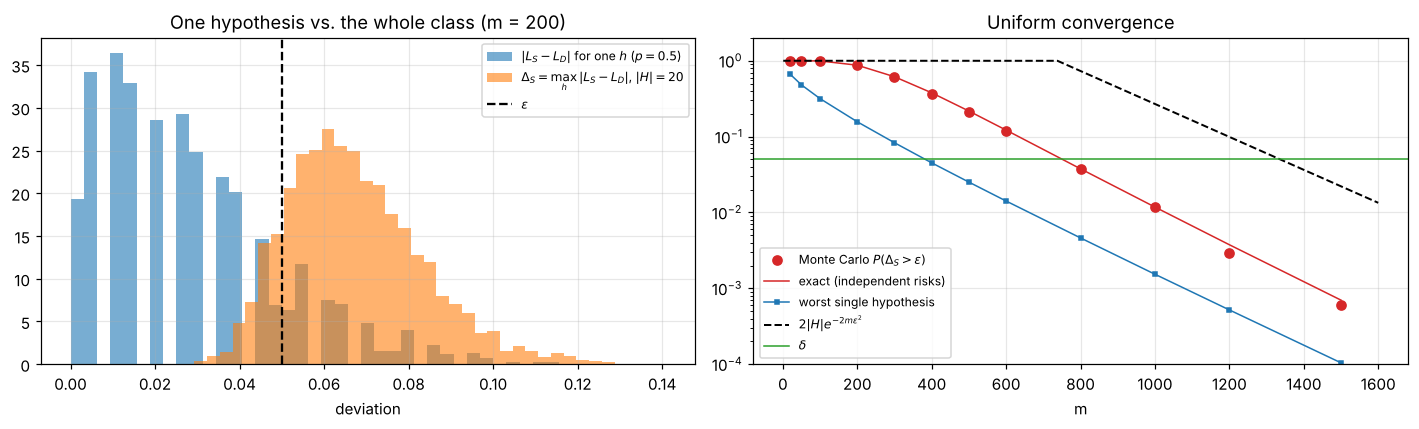

In [8]:
m_show = 200
E = make_rng(31).binomial(m_show, P_H, size=(5000, K3))
delta_s = np.abs(E / m_show - P_H).max(axis=1)
one_h = np.abs(E[:, -1] / m_show - P_H[-1])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.hist(one_h, bins=40, alpha=0.6, density=True, label=rf"$|L_S-L_D|$ for one $h$ ($p={P_H[-1]}$)")
ax.hist(delta_s, bins=40, alpha=0.6, density=True, label=rf"$\Delta_S=\max_h|L_S-L_D|$, $|H|={K3}$")
ax.axvline(EPS, color="k", ls="--", label=r"$\varepsilon$")
ax.set_xlabel("deviation"); ax.set_title(f"One hypothesis vs. the whole class (m = {m_show})"); ax.legend(fontsize=8)
ax = axes[1]
mm = np.arange(1, 1601)
ax.plot(M_UC, uc_mc, "o", color="tab:red", label=r"Monte Carlo $P(\Delta_S>\varepsilon)$")
ax.plot(M_UC, uc_ex, "-", color="tab:red", lw=1, label="exact (independent risks)")
ax.plot(M_UC, single_worst, "s-", ms=3, color="tab:blue", lw=1, label="worst single hypothesis")
ax.plot(mm, hoeffding(mm, EPS, K3), "k--", lw=1.3, label=r"$2|H|e^{-2m\varepsilon^2}$")
ax.axhline(DELTA, color="tab:green", lw=1, label=r"$\delta$")
ax.set_yscale("log"); ax.set_ylim(1e-4, 2); ax.set_xlabel("m"); ax.set_title("Uniform convergence"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


**Observation.** The probability that **some** hypothesis deviates by more than $\varepsilon$ is much larger than for any single hypothesis: at $m = 200$ it is $0.87$ against $0.16$ for the worst single hypothesis, and at $m = 500$ it is $0.21$ against $0.025$. The histogram at $m=200$ shows that $\Delta_S$ is shifted to the right of the deviation of one hypothesis. Monte Carlo and exact values agree within $0.01$. $P(\Delta_S>\varepsilon)$ drops below $\delta = 0.05$ between $m=600$ and $m=800$, while the bound $2|\mathcal H|e^{-2m\varepsilon^2}$ stays at 1 until $m\approx 740$ and reaches $\delta$ only at $m = 1337$.

**Explanation.** $\Delta_S$ is a maximum: it is enough that one of the 20 empirical risks is unlucky. If each hypothesis fails with a small probability $q$, at least one of $K$ independent hypotheses fails with probability $1-(1-q)^K \approx Kq$ when $Kq$ is small, which is exactly the union bound. The bound multiplies Hoeffding by $|\mathcal H|$, and both factors are pessimistic, hence the gap.

**Link to the course.** ERM chooses its hypothesis using the same sample $S$, so controlling one fixed $h$ is not enough: we need $|L_S(h)-L_{\mathcal D}(h)| \le \varepsilon$ **for all** $h$ simultaneously ($\varepsilon$-representativeness). Hoeffding + union bound give exactly the uniform convergence property of finite classes, with $m^{UC}_{\mathcal H}(\varepsilon,\delta) \le \lceil \ln(2|\mathcal H|/\delta)/(2\varepsilon^2) \rceil$.

## 4. Effect of the size of the hypothesis class

We repeat the uniform-convergence experiment for $|\mathcal H| \in \{5, 10, 50, 100, 500\}$, always with true risks spread between $0.05$ and $0.5$. The exact curves are computed on a grid of step 20 and checked by Monte Carlo at 10 values of $m$.

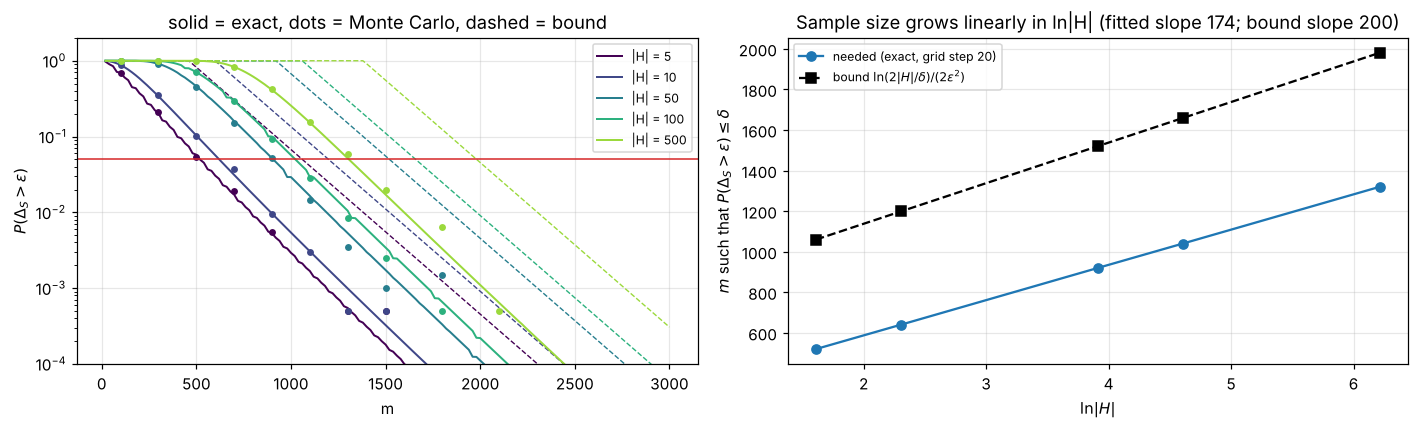

In [9]:
K_LIST = [5, 10, 50, 100, 500]
M_K = np.arange(20, 3001, 20)
R4 = 2_000
rng = make_rng(4)
p_class = {K: np.linspace(0.05, 0.5, K) for K in K_LIST}   # same range of true risks for every class size

uc_K_ex = {K: np.array([exact_uc_fail(m, p_class[K], EPS) for m in M_K]) for K in K_LIST}
M_K_MC = np.array([100, 300, 500, 700, 900, 1100, 1300, 1500, 1800, 2100])
uc_K_mc = {}
for K in K_LIST:
    vals = []
    for m in M_K_MC:
        E = rng.binomial(m, p_class[K], size=(R4, K))
        vals.append(np.mean(is_large_deviation(E, m, p_class[K], EPS).any(axis=1)))
    uc_K_mc[K] = np.array(vals)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = dict(zip(K_LIST, plt.cm.viridis(np.linspace(0, 0.85, len(K_LIST)))))
ax = axes[0]
for K in K_LIST:
    ax.plot(M_K, uc_K_ex[K], "-", color=colors[K], lw=1.3, label=f"|H| = {K}")
    ax.plot(M_K_MC, uc_K_mc[K], "o", ms=3.5, color=colors[K])
    ax.plot(M_K, hoeffding(M_K, EPS, K), "--", color=colors[K], lw=0.9)
ax.axhline(DELTA, color="tab:red", lw=1)
ax.set_yscale("log"); ax.set_ylim(1e-4, 2); ax.set_xlabel("m"); ax.set_ylabel(r"$P(\Delta_S>\varepsilon)$")
ax.set_title("solid = exact, dots = Monte Carlo, dashed = bound"); ax.legend(fontsize=8)

ax = axes[1]
m_need = np.array([M_K[np.argmax(uc_K_ex[K] <= DELTA)] for K in K_LIST])
m_theo = np.array([log(2 * K / DELTA) / (2 * EPS**2) for K in K_LIST])
lnK = np.log(K_LIST)
ax.plot(lnK, m_need, "o-", color="tab:blue", label="needed (exact, grid step 20)")
ax.plot(lnK, m_theo, "s--", color="k", label=r"bound $\ln(2|H|/\delta)/(2\varepsilon^2)$")
slope = np.polyfit(lnK, m_need, 1)[0]
ax.set_xlabel(r"$\ln|H|$"); ax.set_ylabel(r"$m$ such that $P(\Delta_S>\varepsilon)\leq\delta$")
ax.set_title(f"Sample size grows linearly in ln|H| (fitted slope {slope:.0f}; bound slope {1/(2*EPS**2):.0f})")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


**Observation.** For a fixed $m$, $P(\Delta_S > \varepsilon)$ increases with $|\mathcal H|$: the curves are shifted to the right, but by a moderate amount. The sample size needed to reach $\delta = 0.05$ goes from 520 ($|\mathcal H|=5$) to 1320 ($|\mathcal H|=500$): 100 times more hypotheses only cost about 2.5 times more data. Plotted against $\ln|\mathcal H|$, these values lie on a straight line with slope about 174, close to the slope $1/(2\varepsilon^2) = 200$ of the bound. The Monte Carlo dots fall on the exact curves, up to Monte Carlo noise for probabilities below about $0.005$ (with 2 000 runs, such small probabilities are estimated from only a few failures).

**Explanation.** A larger class gives more chances that one empirical risk is far from its true value, so simultaneous control is harder. But the probability of failure of each hypothesis decreases exponentially in $m$, so multiplying the number of hypotheses by $K$ only requires adding about $\ln K/(2\varepsilon^2)$ examples to compensate: the dependence is logarithmic.

**Link to the course.** Yes, a larger hypothesis class generally requires more data, which is the estimation side of the bias-complexity tradeoff (CM4). The experiment reproduces the $\ln|\mathcal H|$ term of $m \ge \ln(2|\mathcal H|/\delta)/(2\varepsilon^2)$: the bound has the right **shape** (linear in $\ln|\mathcal H|$), even if it is too large in absolute value (Section 5).

## 5. Experimental sample complexity

For $\varepsilon = \delta = 0.05$, we find the smallest tested $m$ (grid of step 20) such that the Monte Carlo estimate of $P(\Delta_S>\varepsilon)$ is at most $\delta$, and compare it with the exact value on the same grid and with the theoretical sufficient size $\lceil \ln(2|\mathcal H|/\delta)/(2\varepsilon^2)\rceil$.

In [10]:
M_SC = np.arange(20, 3001, 20)       # tested sample sizes
R5 = 4_000
rng = make_rng(5)
print(f"eps = {EPS}, delta = {DELTA}, Monte Carlo with {R5} samples per m")
print(f"{'|H|':>5} | {'m (experiment)':>14} | {'m (exact)':>9} | {'m (bound)':>9} | {'bound / experiment':>18}")
sc_rows = []
for K in K_LIST:
    m_exp = None
    for m in M_SC:
        if m < 0.4 * log(2 * K / DELTA) / (2 * EPS**2):
            continue                          # far below the transition: skip to save time
        E = rng.binomial(m, p_class[K], size=(R5, K))
        if np.mean(is_large_deviation(E, m, p_class[K], EPS).any(axis=1)) <= DELTA:
            m_exp = m
            break
    m_ex = M_K[np.argmax(uc_K_ex[K] <= DELTA)]
    m_b = ceil(log(2 * K / DELTA) / (2 * EPS**2))
    sc_rows.append((K, m_exp, m_ex, m_b))
    print(f"{K:>5} | {m_exp:>14} | {m_ex:>9} | {m_b:>9} | {m_b / m_exp:>18.2f}")


eps = 0.05, delta = 0.05, Monte Carlo with 4000 samples per m
  |H| | m (experiment) | m (exact) | m (bound) | bound / experiment
    5 |            560 |       520 |      1060 |               1.89
   10 |            620 |       640 |      1199 |               1.93


   50 |            920 |       920 |      1521 |               1.65


  100 |           1040 |      1040 |      1659 |               1.60


  500 |           1300 |      1320 |      1981 |               1.52


In [11]:
# Extreme case: K hypotheses that are perfectly correlated (same errors on every sample).
# Then max_h |L_S(h) - L_D(h)| is the deviation of a single hypothesis: |H| does not matter at all.
K = 500
rng = make_rng(51)
m = 600
E1 = rng.binomial(m, 0.5, size=R5)
corr = np.mean(is_large_deviation(E1, m, 0.5, EPS))              # copies of one hypothesis with p = 0.5
indep = exact_uc_fail(m, p_class[K], EPS)
print(f"m = {m}, |H| = {K}:  P(Delta > eps) = {corr:.4f} (identical hypotheses)  vs  {indep:.4f} (independent)"
      f"  vs  bound {hoeffding(m, EPS, K):.1f}")


m = 600, |H| = 500:  P(Delta > eps) = 0.0132 (identical hypotheses)  vs  0.9620 (independent)  vs  bound 1.0


**Observation.** The experimental sample sizes (560, 620, 920, 1040, 1300) agree with the exact ones up to one or two grid steps, which is the Monte Carlo precision near $\delta$. The theoretical bound is always larger, by a factor between 1.5 and 1.9, and the factor tends to decrease as $|\mathcal H|$ grows. In the extreme case where the 500 hypotheses are identical copies, $P(\Delta_S>\varepsilon)$ at $m=600$ is only $0.013$, against $0.96$ for 500 independent hypotheses, while the bound is still 1.

**Explanation.** The bound loses twice: (1) Hoeffding ignores the actual variance $p(1-p)$, which is smaller than $1/4$ for most hypotheses here; (2) the union bound treats the failures of the hypotheses as if they could never happen at the same time, and it ignores correlations. Our hypotheses are independent, which is the case where the union bound is the least pessimistic; in real classes, hypotheses that make similar predictions have strongly correlated errors (as in the thresholds of HW1), and the true $m$ is even further below the bound.

**Link to the course.** $\lceil \ln(2|\mathcal H|/\delta)/(2\varepsilon^2)\rceil$ is a **sufficient** sample size: with that many examples the guarantee holds for every distribution, but it is not the minimal size for a particular problem. This is why the course writes $m^{UC}_{\mathcal H}(\varepsilon,\delta) \le \dots$ and not "$=$".

# Part II — Simulating No-Free-Lunch

Domain $\mathcal X = \{1,\dots,N\}$ with the uniform distribution. In every repetition a **new** target $f$ is drawn with $f(x)\sim\text{Bernoulli}(1/2)$ independently for each $x$, so every labeling of $\mathcal X$ is equally likely. The learner memorizes the labels of the points it has seen and predicts a default label on the others.

## 6. Seen and unseen inputs

A fixed $x$ is missed by one draw with probability $1-1/N$, hence by $m$ independent draws with probability $(1-1/N)^m$. Writing the unseen fraction as $\frac1N\sum_x \mathbb 1[x \text{ unseen}]$ and using linearity of expectation,
$$\mathbb E[\text{fraction of unseen points}] = \frac1N\sum_{x}P(x\text{ unseen}) = \Big(1-\frac1N\Big)^m.$$

In [12]:
def draw_samples(Nd, m, n_rep, rng):
    # m points drawn uniformly (with replacement) from {0, ..., Nd-1}; returns the boolean "seen" mask
    idx = rng.integers(0, Nd, size=(n_rep, m))
    seen = np.zeros((n_rep, Nd), dtype=bool)
    np.put_along_axis(seen, idx, True, axis=1)
    return idx, seen

M_NFL = np.array([0, 5, 10, 20, 50, 100, 150, 200, 300, 400, 500, 750, 1000])
rng = make_rng(6)
unseen = {}
for Nd in N_LIST:
    unseen[Nd] = np.array([1 - draw_samples(Nd, m, R2, rng)[1].mean() if m > 0 else 1.0 for m in M_NFL])

print(f"{'m':>5} | " + " | ".join(f"{'N='+str(Nd)+' MC':>10} {'theory':>7}" for Nd in N_LIST))
for i, m in enumerate(M_NFL):
    print(f"{m:>5} | " + " | ".join(f"{unseen[Nd][i]:>10.4f} {(1 - 1/Nd)**m:>7.4f}" for Nd in N_LIST))


    m |    N=20 MC  theory |   N=100 MC  theory |   N=500 MC  theory
    0 |     1.0000  1.0000 |     1.0000  1.0000 |     1.0000  1.0000
    5 |     0.7739  0.7738 |     0.9511  0.9510 |     0.9900  0.9900
   10 |     0.5981  0.5987 |     0.9044  0.9044 |     0.9802  0.9802
   20 |     0.3599  0.3585 |     0.8181  0.8179 |     0.9608  0.9608
   50 |     0.0751  0.0769 |     0.6054  0.6050 |     0.9048  0.9047
  100 |     0.0060  0.0059 |     0.3665  0.3660 |     0.8186  0.8186
  150 |     0.0004  0.0005 |     0.2219  0.2215 |     0.7406  0.7406
  200 |     0.0000  0.0000 |     0.1338  0.1340 |     0.6702  0.6701
  300 |     0.0000  0.0000 |     0.0489  0.0490 |     0.5483  0.5485
  400 |     0.0000  0.0000 |     0.0181  0.0180 |     0.4489  0.4490
  500 |     0.0000  0.0000 |     0.0066  0.0066 |     0.3677  0.3675
  750 |     0.0000  0.0000 |     0.0006  0.0005 |     0.2231  0.2228
 1000 |     0.0000  0.0000 |     0.0000  0.0000 |     0.1351  0.1351


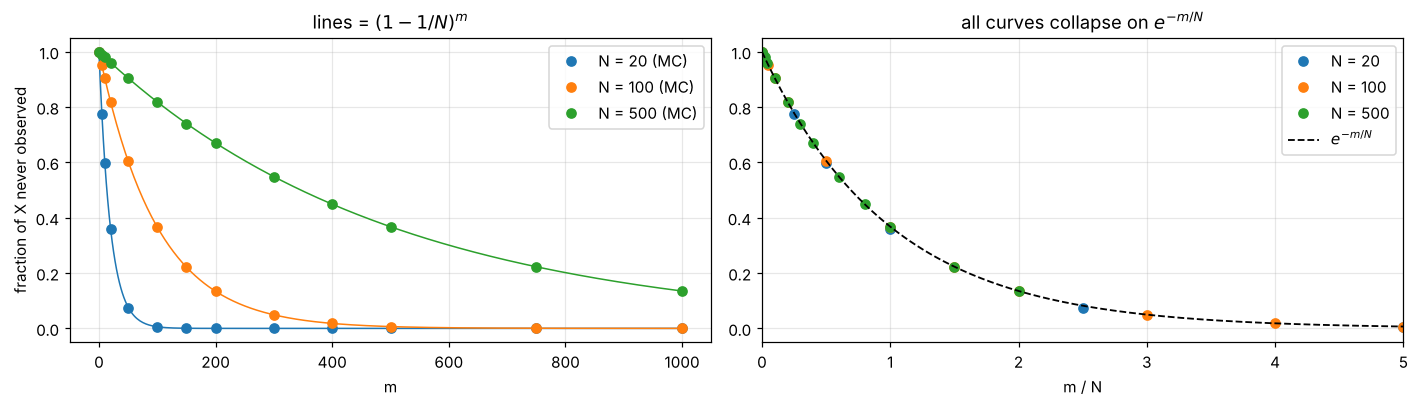

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
mm = np.linspace(0, 1000, 400)
for Nd, c in zip(N_LIST, ["tab:blue", "tab:orange", "tab:green"]):
    axes[0].plot(M_NFL, unseen[Nd], "o", color=c, label=f"N = {Nd} (MC)")
    axes[0].plot(mm, (1 - 1/Nd) ** mm, "-", color=c, lw=1)
    axes[1].plot(M_NFL / Nd, unseen[Nd], "o", color=c, label=f"N = {Nd}")
r = np.linspace(0, 5, 200)
axes[1].plot(r, np.exp(-r), "k--", lw=1.2, label=r"$e^{-m/N}$")
axes[0].set_xlabel("m"); axes[0].set_ylabel("fraction of X never observed"); axes[0].legend()
axes[0].set_title(r"lines = $(1-1/N)^m$")
axes[1].set_xlabel("m / N"); axes[1].set_xlim(0, 5); axes[1].legend(); axes[1].set_title("all curves collapse on $e^{-m/N}$")
plt.tight_layout(); plt.show()


**Observation.** The simulated fractions match $(1-1/N)^m$ to the third decimal for all $N$. Seeing $m = N$ examples is far from seeing the whole domain: for $N=100$, $m=100$ draws leave $36.6\%$ of the points unseen, and $m=500$ draws still leave $0.66\%$. When the unseen fraction is plotted against $m/N$, the three curves fall on the same curve $e^{-m/N}$.

**Explanation.** The draws are with replacement, so many of them repeat points already seen (the "coupon collector" effect). Since $(1-1/N)^m = e^{m\ln(1-1/N)} \approx e^{-m/N}$, what matters is the ratio $m/N$: a larger domain needs proportionally more data to be covered.

**Link to the course.** In the proof of the No-Free-Lunch theorem, $|C| = 2m$ guarantees that at least half of the domain is unseen. Here the unseen fraction is even larger because of repetitions: $(1-\frac{1}{2m})^m \approx e^{-1/2} \approx 0.61 > 1/2$.

## 7. Error on unseen inputs

The memorization learner is correct on every seen point. On an unseen point it predicts 0, which is wrong exactly when $f(x)=1$, i.e. with probability $1/2$, independently of the sample. Therefore
$$\mathbb E[L_{\mathcal D}(A(S))] = \frac1N\sum_x P(x\text{ unseen})\cdot\frac12 = \frac12\Big(1-\frac1N\Big)^m.$$

In [14]:
def nfl_experiment(Nd, m, n_rep, rng, rule="zero"):
    # New random target f ~ Bernoulli(1/2)^N for every repetition; memorize seen labels, apply `rule` elsewhere.
    f = rng.integers(0, 2, size=(n_rep, Nd))
    _, seen = draw_samples(Nd, m, n_rep, rng)
    if rule == "zero":
        guess = np.zeros_like(f)
    elif rule == "one":
        guess = np.ones_like(f)
    elif rule == "random":
        guess = rng.integers(0, 2, size=f.shape)
    pred = np.where(seen, f, guess)
    return np.mean(pred != f, axis=1)          # true risk over the whole uniform domain

rng = make_rng(7)
risk_mem = {Nd: np.array([nfl_experiment(Nd, m, R2, rng).mean() for m in M_NFL]) for Nd in N_LIST}
print(f"{'m':>5} | " + " | ".join(f"{'N='+str(Nd)+' MC':>10} {'theory':>7}" for Nd in N_LIST))
for i, m in enumerate(M_NFL):
    print(f"{m:>5} | " + " | ".join(f"{risk_mem[Nd][i]:>10.4f} {0.5*(1 - 1/Nd)**m:>7.4f}" for Nd in N_LIST))


    m |    N=20 MC  theory |   N=100 MC  theory |   N=500 MC  theory
    0 |     0.5009  0.5000 |     0.4987  0.5000 |     0.5000  0.5000
    5 |     0.3877  0.3869 |     0.4746  0.4755 |     0.4946  0.4950
   10 |     0.2974  0.2994 |     0.4512  0.4522 |     0.4896  0.4901
   20 |     0.1810  0.1792 |     0.4078  0.4090 |     0.4801  0.4804
   50 |     0.0381  0.0385 |     0.3028  0.3025 |     0.4521  0.4524
  100 |     0.0033  0.0030 |     0.1839  0.1830 |     0.4092  0.4093
  150 |     0.0002  0.0002 |     0.1109  0.1107 |     0.3705  0.3703
  200 |     0.0000  0.0000 |     0.0664  0.0670 |     0.3346  0.3350
  300 |     0.0000  0.0000 |     0.0241  0.0245 |     0.2743  0.2742
  400 |     0.0000  0.0000 |     0.0088  0.0090 |     0.2242  0.2245
  500 |     0.0000  0.0000 |     0.0033  0.0033 |     0.1836  0.1838
  750 |     0.0000  0.0000 |     0.0003  0.0003 |     0.1115  0.1114
 1000 |     0.0000  0.0000 |     0.0000  0.0000 |     0.0676  0.0675


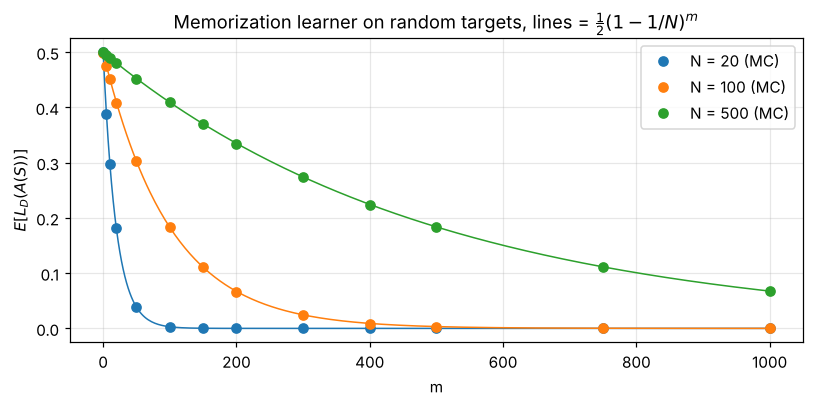

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
mm = np.linspace(0, 1000, 400)
for Nd, c in zip(N_LIST, ["tab:blue", "tab:orange", "tab:green"]):
    ax.plot(M_NFL, risk_mem[Nd], "o", color=c, label=f"N = {Nd} (MC)")
    ax.plot(mm, 0.5 * (1 - 1/Nd) ** mm, "-", color=c, lw=1)
ax.set_xlabel("m"); ax.set_ylabel(r"$E[L_D(A(S))]$"); ax.legend()
ax.set_title(r"Memorization learner on random targets, lines = $\frac{1}{2}(1-1/N)^m$")
plt.tight_layout(); plt.show()


**Observation.** The simulated expected risks agree with $\frac12(1-1/N)^m$ within $0.002$ for every $N$ and $m$. The risk starts at $0.5$ (random guessing) and only decreases as the domain gets covered: for $N = 500$ it is still $0.41$ after $m=100$ examples and $0.18$ after $m=500$.

**Explanation.** The learner does not generalize at all: it only "knows" the labels it has seen. The whole risk comes from unseen points, on which it is wrong half of the time on average, so the risk is exactly half of the unseen fraction of Section 6.

**Link to the course.** With $m = N/2$ (the setting of the NFL theorem, $|C| = 2m$), the formula gives $\frac12 e^{-1/2} \approx 0.30 \ge \frac14$, consistent with the lower bound $\mathbb E[L_{\mathcal D}(A(S))] \ge \frac14$ obtained in the proof. Learning only "happens" here because $m$ eventually becomes much larger than $N$, i.e. by memorizing the whole domain, which is impossible for an infinite or very large $\mathcal X$.

## 8. Changing the prediction on unseen inputs

We compare three rules for unseen points: always predict 0, always predict 1, predict a random Bernoulli(1/2) label. Each rule uses its own random targets; then the rules "0" and "1" are also compared on exactly the same targets and samples.

In [16]:
RULES = ["zero", "one", "random"]
M8 = [10, 50, 100, 200]
print(f"N = {N}, mean true risk over {R2} random targets (std of the risk in brackets)")
print(f"{'m':>5} | " + " | ".join(f"{r:>17}" for r in RULES) + f" | {'theory':>7}")
for m in M8:
    out = []
    for j, rule in enumerate(RULES):
        risks = nfl_experiment(N, m, R2, make_rng(80 + j), rule=rule)
        out.append(f"{risks.mean():.4f} ({risks.std():.4f})")
    print(f"{m:>5} | " + " | ".join(f"{o:>17}" for o in out) + f" | {0.5*(1-1/N)**m:>7.4f}")

# Paired comparison on the SAME targets and samples: "zero" vs "one"
rng = make_rng(85)
m = 50
f = rng.integers(0, 2, size=(R2, N))
_, seen = draw_samples(N, m, R2, rng)
r0 = np.mean(np.where(seen, f, 0) != f, axis=1)
r1 = np.mean(np.where(seen, f, 1) != f, axis=1)
print(f"\nm = {m}, same targets for both rules: rule 0 better on {np.mean(r0 < r1):.1%}, "
      f"rule 1 better on {np.mean(r1 < r0):.1%}, tie on {np.mean(r0 == r1):.1%}; mean difference {np.mean(r0 - r1):+.4f}")

# The picture changes completely as soon as the targets are NOT uniform over all labelings.
f_mostly1 = (rng.random((R2, N)) < 0.9).astype(int)        # targets with 90% of 1-labels
r0b = np.mean(np.where(seen, f_mostly1, 0) != f_mostly1, axis=1).mean()
r1b = np.mean(np.where(seen, f_mostly1, 1) != f_mostly1, axis=1).mean()
print(f"targets with P(f(x)=1) = 0.9: rule 0 -> {r0b:.4f}, rule 1 -> {r1b:.4f}")


N = 100, mean true risk over 5000 random targets (std of the risk in brackets)
    m |              zero |               one |            random |  theory
   10 |   0.4512 (0.0468) |   0.4523 (0.0478) |   0.4519 (0.0475) |  0.4522


   50 |   0.3023 (0.0407) |   0.3033 (0.0406) |   0.3019 (0.0398) |  0.3025
  100 |   0.1828 (0.0337) |   0.1841 (0.0345) |   0.1826 (0.0332) |  0.1830
  200 |   0.0662 (0.0229) |   0.0669 (0.0227) |   0.0669 (0.0233) |  0.0670

m = 50, same targets for both rules: rule 0 better on 48.1%, rule 1 better on 46.6%, tie on 5.3%; mean difference -0.0009
targets with P(f(x)=1) = 0.9: rule 0 -> 0.5443, rule 1 -> 0.0606


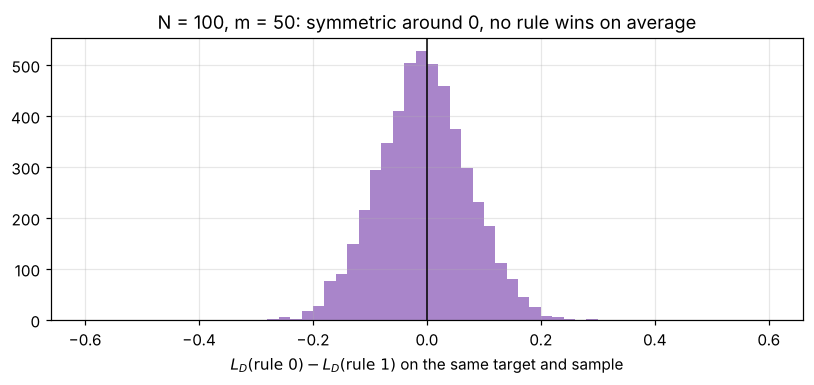

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(r0 - r1, bins=np.arange(-0.6, 0.62, 0.02), color="tab:purple", alpha=0.8)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel(r"$L_D(\mathrm{rule}\ 0) - L_D(\mathrm{rule}\ 1)$ on the same target and sample")
ax.set_title(f"N = {N}, m = 50: symmetric around 0, no rule wins on average")
plt.tight_layout(); plt.show()


**Observation.** The three rules have the same mean risk, equal to $\frac12(1-1/N)^m$ (for example $0.302$, $0.303$, $0.302$ against $0.3025$ at $m=50$), and almost the same spread. On the same targets, rule 0 beats rule 1 on $48.1\%$ of the cases and loses on $46.6\%$ (ties $5.3\%$); the mean difference is $-0.0009$ and the histogram of differences is symmetric around 0. However, if the targets are drawn with $P(f(x)=1)=0.9$ instead of $1/2$, rule 1 has risk $0.061$ while rule 0 has risk $0.544$.

**Explanation.** When all labelings are equally likely, the label of an unseen point is independent of everything the learner observed and is 0 or 1 with probability $1/2$. Any prediction, deterministic or random, is therefore right half of the time on average. A rule can win on some targets (rule 1 is perfect when $f\equiv 1$) only because it loses on the "mirror" targets, exactly like the pairs $(f_i, f_i')$ of the NFL proof. As soon as the targets are not uniform over all labelings, some rules become much better than others.

**Link to the course.** This is the No-Free-Lunch principle: averaged over all possible tasks, no learner is better than another on unseen inputs, and the training sample alone cannot tell which unseen labels are correct. A learner can only beat this by encoding an assumption about which targets are likely (here "mostly 1"), i.e. an inductive bias.

# Part III — Introducing prior knowledge

## 9. Learning with a matching inductive bias

Same domain $\mathcal X = \{1,\dots,N\}$ with $N = 100$, but the target is now a threshold $f_\theta(x) = \mathbb 1[x>\theta]$, with a new $\theta$ drawn uniformly in $\{1,\dots,N-1\}$ in every repetition. The learner uses ERM over $\mathcal H = \{h_t(x) = \mathbb 1[x>t] : t\in\{1,\dots,N-1\}\}$ (99 hypotheses), so realizability holds.

**ERM.** Every $t$ between $\ell$ = the largest observed point with label 0 and $u-1$, where $u$ = the smallest observed point with label 1, has zero empirical risk, and $\theta$ always lies in $[\ell, u-1]$. We return the midpoint $\hat t = \lfloor(\ell + u - 1)/2\rfloor$. Since $h_{\hat t}$ and $f_\theta$ disagree on exactly $|\hat t-\theta|$ points of the uniform domain, $L_{\mathcal D}(h_{\hat t}) = |\hat t - \theta|/N$.

In [18]:
def threshold_task(Nd, m, n_rep, rng):
    # Target f_theta(x) = 1[x > theta] on X = {1..Nd}, theta ~ Uniform{1..Nd-1}; m points drawn uniformly.
    theta = rng.integers(1, Nd, size=n_rep)
    x = rng.integers(1, Nd + 1, size=(n_rep, m))
    y = (x > theta[:, None]).astype(int)
    return theta, x, y

def erm_threshold(x, y, Nd):
    # ERM over H = {h_t(x) = 1[x > t] : t in {1..Nd-1}}. Realizable, so every t in [lo, hi] has L_S = 0:
    # lo = largest observed point with label 0, hi = (smallest observed point with label 1) - 1.
    lo = np.maximum(1, np.where(y == 0, x, 1).max(axis=1))
    hi = np.minimum(Nd - 1, np.where(y == 1, x, Nd).min(axis=1) - 1)
    t_hat = (lo + hi) // 2                      # midpoint of the consistent interval
    ls = np.mean((x > t_hat[:, None]).astype(int) != y, axis=1)
    return t_hat, ls

M9 = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
rng = make_rng(9)
thr = {}
for m in M9:
    theta, x, y = threshold_task(N, m, R2, rng)
    t_hat, ls = erm_threshold(x, y, N)
    risk = np.abs(t_hat - theta) / N            # h_t and f_theta disagree exactly on |t - theta| points
    thr[m] = (ls, risk)

print(f"N = {N}, threshold targets, ERM over threshold classifiers ({R2} repetitions)")
print(f"{'m':>5} | {'max L_S':>7} | {'E[L_D] threshold ERM':>20} | {'P(L_D = 0)':>10} | {'E[L_D] memorizer (Part II)':>26}")
for m in M9:
    ls, risk = thr[m]
    print(f"{m:>5} | {ls.max():>7.3f} | {risk.mean():>20.4f} | {np.mean(risk == 0):>10.3f} | {0.5*(1-1/N)**m:>26.4f}")


N = 100, threshold targets, ERM over threshold classifiers (5000 repetitions)
    m | max L_S | E[L_D] threshold ERM | P(L_D = 0) | E[L_D] memorizer (Part II)
    1 |   0.000 |               0.1640 |      0.019 |                     0.4950
    2 |   0.000 |               0.1243 |      0.033 |                     0.4900
    5 |   0.000 |               0.0712 |      0.057 |                     0.4755
   10 |   0.000 |               0.0415 |      0.102 |                     0.4522
   20 |   0.000 |               0.0226 |      0.194 |                     0.4090
   50 |   0.000 |               0.0092 |      0.398 |                     0.3025
  100 |   0.000 |               0.0041 |      0.639 |                     0.1830
  200 |   0.000 |               0.0014 |      0.864 |                     0.0670
  500 |   0.000 |               0.0001 |      0.993 |                     0.0033
 1000 |   0.000 |               0.0000 |      1.000 |                     0.0000


**Observation.** ERM always reaches zero training error (column "max $L_S$"), and its true risk is far below the memorizer's: $0.0415$ against $0.452$ at $m = 10$, $0.0041$ against $0.183$ at $m = 100$. With only 50 examples, about 60% of the domain is still unseen, yet the learned threshold is exactly right in $40\%$ of the runs and the mean error is below $1\%$; with $m = 200$, it is exactly right in $86\%$ of the runs.

**Explanation.** A threshold function is entirely determined by one number. Two observed points, the largest 0 and the smallest 1, are enough to pin $\theta$ inside a small interval, and the assumption "the target is a threshold" fixes the labels of **all** the unseen points outside this interval: every unseen point to the left of $\ell$ must be 0 and every one to the right of $u$ must be 1. Errors are only possible on the few points between $\ell$ and $u$.

**Link to the course.** This is a finite class ($|\mathcal H| = 99$) under realizability, the setting of CM1–CM2, and the target belongs to the class: the inductive bias **matches** the problem.

## 10. Random targets vs. structured targets

To separate the role of the **target structure** from the role of the **learner's bias**, we compare four combinations on the same domain ($N=100$):

| | memorizer (no bias) | threshold ERM (threshold bias) |
|---|---|---|
| random targets | (a) Part II | wrong bias |
| threshold targets | structure but no bias | (b) matching bias |

For "random targets + threshold ERM", the learner picks the threshold with the smallest training error (1000 repetitions).

In [19]:
def memorizer_on_thresholds(Nd, m, n_rep, rng):
    # Structured (threshold) targets, but a learner with NO inductive bias: memorize, predict 0 on unseen points.
    theta = rng.integers(1, Nd, size=n_rep)
    f = (np.arange(1, Nd + 1)[None, :] > theta[:, None]).astype(int)
    _, seen = draw_samples(Nd, m, n_rep, rng)
    return np.mean(np.where(seen, f, 0) != f, axis=1)

def threshold_erm_on_random(Nd, m, n_rep, rng):
    # Random targets, but a learner that insists on thresholds (best threshold on the sample, ties -> smallest t).
    f = rng.integers(0, 2, size=(n_rep, Nd))
    idx = rng.integers(0, Nd, size=(n_rep, m))
    y = np.take_along_axis(f, idx, axis=1)
    ts = np.arange(1, Nd)                                  # candidate thresholds
    xs = idx + 1
    # empirical risk of every threshold: counts of label-1 points <= t and label-0 points > t
    err = np.stack([np.sum((xs > t) != y, axis=1) for t in ts], axis=1)
    t_hat = ts[np.argmin(err, axis=1)]
    pred = (np.arange(1, Nd + 1)[None, :] > t_hat[:, None]).astype(int)
    return np.mean(pred != f, axis=1)

M10 = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
rng_a, rng_b = make_rng(101), make_rng(102)
c_random_mem = np.array([nfl_experiment(N, m, R2, make_rng(100)).mean() for m in M10])
c_thr_erm = np.array([thr[m][1].mean() for m in M10])
c_thr_mem = np.array([memorizer_on_thresholds(N, m, R2, rng_a).mean() for m in M10])
c_random_erm = np.array([threshold_erm_on_random(N, m, 1000, rng_b).mean() for m in M10])

print(f"N = {N}: mean true risk")
print(f"{'m':>5} | {'random f + memorizer':>20} | {'threshold f + threshold ERM':>27} | {'threshold f + memorizer':>23} | {'random f + threshold ERM':>24}")
for i, m in enumerate(M10):
    print(f"{m:>5} | {c_random_mem[i]:>20.4f} | {c_thr_erm[i]:>27.4f} | {c_thr_mem[i]:>23.4f} | {c_random_erm[i]:>24.4f}")
slope = np.polyfit(np.log(M10[3:8]), np.log(c_thr_erm[3:8]), 1)[0]
print(f"\nlog-log slope of the threshold-ERM curve for 10 <= m <= 200: {slope:.2f}")


N = 100: mean true risk
    m | random f + memorizer | threshold f + threshold ERM | threshold f + memorizer | random f + threshold ERM
    1 |               0.4952 |                      0.1640 |                  0.4961 |                   0.4932
    2 |               0.4904 |                      0.1243 |                  0.4958 |                   0.4954
    5 |               0.4757 |                      0.0712 |                  0.4776 |                   0.4851
   10 |               0.4523 |                      0.0415 |                  0.4544 |                   0.4847
   20 |               0.4091 |                      0.0226 |                  0.4080 |                   0.4725
   50 |               0.3020 |                      0.0092 |                  0.3034 |                   0.4611
  100 |               0.1827 |                      0.0041 |                  0.1840 |                   0.4471
  200 |               0.0673 |                      0.0014 |                  0.

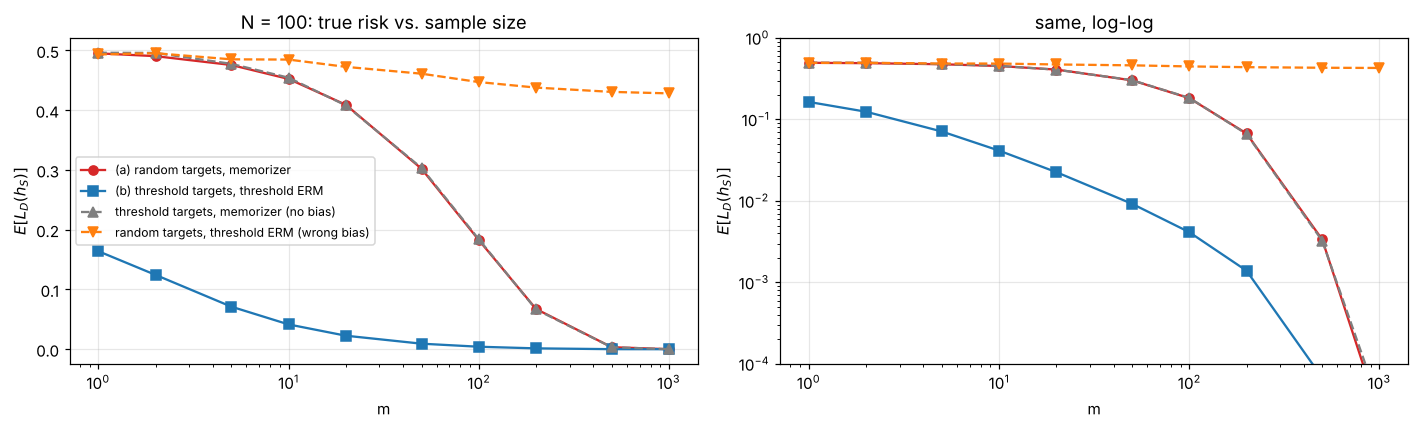

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.plot(M10, c_random_mem, "o-", color="tab:red", label="(a) random targets, memorizer")
    ax.plot(M10, c_thr_erm, "s-", color="tab:blue", label="(b) threshold targets, threshold ERM")
    ax.plot(M10, c_thr_mem, "^--", color="tab:gray", label="threshold targets, memorizer (no bias)")
    ax.plot(M10, c_random_erm, "v--", color="tab:orange", label="random targets, threshold ERM (wrong bias)")
    ax.set_xscale("log"); ax.set_yscale(scale); ax.set_xlabel("m"); ax.set_ylabel(r"$E[L_D(h_S)]$")
    if scale == "log": ax.set_ylim(1e-4, 1)
axes[0].legend(fontsize=8); axes[0].set_title(f"N = {N}: true risk vs. sample size")
axes[1].set_title("same, log-log")
plt.tight_layout(); plt.show()


**Observation.** Only the combination "threshold targets + threshold ERM" (b) learns fast: its risk decreases like $1/m$ (log-log slope $-1.11$ for $10\le m\le 200$), and for $10 \le m \le 200$ it is 10 to 50 times smaller than the memorizer's. The memorizer has the same curve $\frac12(1-1/N)^m$ whether the targets are random or thresholds ($0.302$ vs $0.303$ at $m=50$): the structure of the targets does not help a learner that does not use it. Conversely, the threshold learner on random targets stays around $0.43$ even for $m=1000$, when the memorizer already has zero error.

**Explanation.** Generalizing to unseen inputs requires two things at the same time: the targets must have structure, and the learner must assume that structure. For random targets, the best threshold still misclassifies about $43\%$ of the domain, because a random labeling is not close to any threshold: the threshold class has a large **approximation error** on these tasks, and more data cannot fix it. For threshold targets, the memorizer ignores that the label of an unseen point can be deduced from its neighbours, so it wastes the structure.

**Link to the course.** This is the No-Free-Lunch message seen from the positive side (CM4): restricting $\mathcal H$ to thresholds is a prior assumption. When the assumption is true, it removes the unpredictability of unseen labels and gives a small estimation error with few examples. When it is false, it creates an approximation error that no amount of data removes. The choice of $\mathcal H$ is therefore the bias–complexity tradeoff in action.

## 11. Final analysis

**Why $L_S(h)$ concentrates around $L_{\mathcal D}(h)$.** For a fixed $h$, $L_S(h)$ is an average of $m$ i.i.d. 0-1 losses: it is unbiased and its standard deviation is $\sqrt{p(1-p)/m}$ (Section 1). The probability of a deviation larger than $\varepsilon$ decreases exponentially in $m$, as Hoeffding predicts (Section 2).

**Why uniform convergence needs simultaneous control.** ERM selects its hypothesis with the same sample, so it is likely to pick a hypothesis whose empirical risk is luckily low. A guarantee for one fixed $h$ says nothing about the selected one; we need $\Delta_S = \max_h|L_S(h)-L_{\mathcal D}(h)| \le \varepsilon$, which fails much more often than a single deviation (0.87 vs 0.16 at $m=200$, Section 3).

**How $|\mathcal H|$ affects this control.** More hypotheses mean more chances for one of them to deviate, so the needed sample size grows, but only like $\ln|\mathcal H|$: from 520 to 1320 examples when $|\mathcal H|$ goes from 5 to 500 (Section 4).

**Why finite-class bounds can be conservative.** The bound $\lceil\ln(2|\mathcal H|/\delta)/(2\varepsilon^2)\rceil$ was 1.5 to 1.9 times the real need for independent hypotheses and up to 18 times for a single low-risk hypothesis, because Hoeffding ignores the variance and the union bound ignores correlations (Sections 2 and 5). It is a sufficient, distribution-free condition, not the exact sample size.

**Why random targets make unseen labels unpredictable.** When every labeling is equally likely, the label of an unseen point is a fair coin independent of the sample. Every rule (0, 1, random) has the same expected risk $\frac12(1-1/N)^m$ (Sections 7–8).

**What the No-Free-Lunch experiment shows.** The training sample alone cannot determine arbitrary unseen labels: for every target where a rule is right on an unseen point, the mirror target makes it wrong, so no learner beats another on average over all tasks. The memorizer only improves by covering the domain, which requires $m \gg N$ (Section 6).

**How thresholds introduce prior knowledge.** Restricting both the targets and the hypothesis class to thresholds encodes the assumption "labels change only once, from 0 to 1". This turns the labels of unseen points into consequences of the observed ones.

**Why this inductive bias allows generalization.** Under this assumption a few examples locate the boundary, and every unseen point outside a small interval is labeled correctly: the risk drops like $1/m$ (0.4% at $m=100$ against 18% for the memorizer). The same bias is harmful when it is wrong (risk stuck at 0.43 on random targets). Generalization is possible exactly when the inductive bias matches the problem.